<a href="https://colab.research.google.com/github/Alif-dot-svg/Data-Profiling-Assignment/blob/main/TTTC3213_Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Data Profiling of Personal Finance Records

## Team Members
1. ALIS SURAYA BINTI ABDUL KADIR A216388
2. WAN ADNI SYAMIMI BINTI WAN MUSTAFFA A216555
3. MUHAMMAD NUR ALIF BIN JAFRI A216513
4. IFFAH NADHILA BINTI AHMAD JAILANI A194937

## 1. Scenario

This project examines personal income and expense records to assess
whether the data is suitable for spending analysis and budget planning.
The records contain missing values, redundant columns, and transactions
in different currencies that require careful handling.
The profiling asks which data quality issues are present, how they
should be handled, and what limitations remain after cleaning.

## 2. Data Source

Dataset: My Expenses Data  
Uploader: Tharun Prabu  
URL: https://www.kaggle.com/datasets/tharunprabu/my-expenses-data

The CSV was downloaded manually from Kaggle. According to the uploader,
the dataset contains approximately four months of their own income
and expense records.

## Instructions to Run

1. Place `expense_data_1.csv` in the same folder as this notebook.
2. Install pandas, numpy, matplotlib and seaborn.
3. Run all cells from top to bottom.

Installation command:
`pip install pandas numpy matplotlib seaborn`

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")

df_raw = pd.read_csv("expense_data_1.csv")
df = df_raw.copy(deep=True)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Exclude free-text notes from displayed previews for privacy.
display(df.drop(columns=["Note", "Note.1"], errors="ignore").head())

Rows: 277
Columns: 11


,Date,Account,Category,Subcategory,INR,Income/Expense,Amount,Currency,Account.1
0,3/2/2022 10:11,CUB - online payment,Food,NaN,50.0,Expense,50.0,INR,50.0
1,3/2/2022 10:11,CUB - online payment,Other,NaN,300.0,Expense,300.0,INR,300.0
2,3/1/2022 19:50,CUB - online payment,Food,NaN,78.0,Expense,78.0,INR,78.0
3,3/1/2022 18:56,CUB - online payment,Transportation,NaN,30.0,Expense,30.0,INR,30.0
4,3/1/2022 18:22,CUB - online payment,Food,NaN,67.0,Expense,67.0,INR,67.0


## 3. Initial Data Profiling

The initial checks examine dataset dimensions, data types, missing values
and exact duplicate rows. Free-text notes are excluded from displayed
previews because they may contain personal names or sensitive details.

In [ ]:
profile = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Non-missing": df.notna().sum(),
    "Missing": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique(dropna=True)
})

display(profile)

duplicate_count = int(df.duplicated().sum())
print("Exact duplicate rows:", duplicate_count)

,Data type,Non-missing,Missing,Missing (%),Unique values
Date,object,277,0,0.00,240
Account,object,277,0,0.00,2
Category,object,277,0,0.00,13
Subcategory,float64,0,277,100.00,0
Note,object,273,4,1.44,159
INR,float64,277,0,0.00,138
Income/Expense,object,277,0,0.00,2
Note.1,float64,0,277,100.00,0
Amount,float64,277,0,0.00,137
Currency,object,277,0,0.00,2


Exact duplicate rows: 0


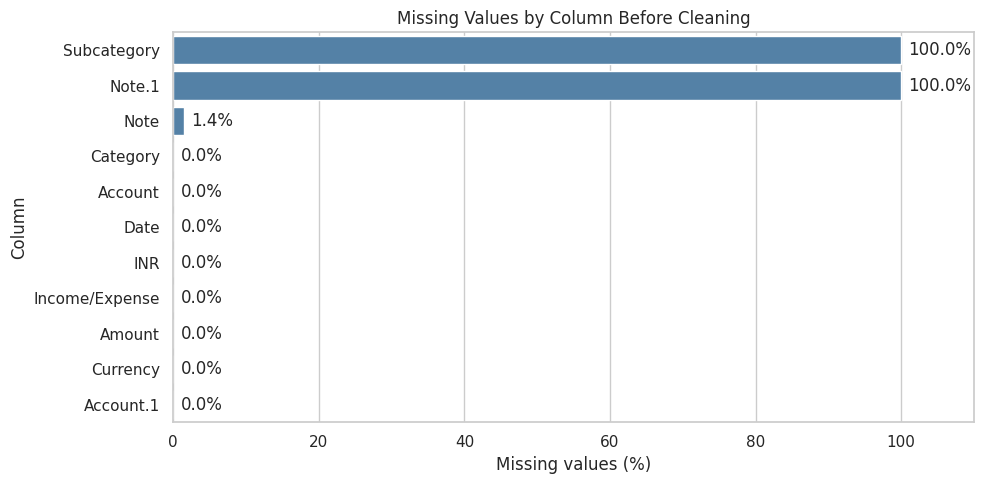

In [ ]:
missing_pct = (
    df_raw.isna().mean().mul(100).sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=missing_pct.values,
    y=missing_pct.index,
    color="steelblue",
    ax=ax
)

ax.set(
    title="Missing Values by Column Before Cleaning",
    xlabel="Missing values (%)",
    ylabel="Column",
    xlim=(0, 110)
)

for i, value in enumerate(missing_pct.values):
    ax.text(value + 1, i, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.show()

### 3.1 Missing-Value Handling

`Subcategory` and `Note.1` are entirely missing. They are removed because
they provide no usable information, and imputing entire columns would
require unsupported assumptions.

Missing values in `Note` are retained and flagged rather than filled
with invented descriptions. A missing note does not automatically make
the transaction amount or date invalid.

In [ ]:
cleaning_log = []

def log_action(action, reason, rows_before, rows_after):
    cleaning_log.append({
        "Action": action,
        "Reason": reason,
        "Rows before": rows_before,
        "Rows after": rows_after
    })

# Remove columns that are entirely missing.
empty_columns = df.columns[df.isna().all()].tolist()

before = len(df)
df = df.drop(columns=empty_columns)

log_action(
    f"Removed empty columns: {empty_columns}",
    "Entirely missing columns contain no usable information.",
    before,
    len(df)
)

# Preserve the distinction between present and missing notes.
df["note_missing"] = df["Note"].isna()

print("Removed columns:", empty_columns)
print("Records with missing notes:", int(df["note_missing"].sum()))

Removed columns: ['Subcategory', 'Note.1']
Records with missing notes: 4


### 3.2 Other Data Quality Checks

The checks cover redundant columns, date parsing, numeric validity,
categorical formatting and exact duplicate rows. A check can be useful
even when it finds no issue. In this dataset, the date and numeric
conversions did not fail, transaction types were valid, and no exact
duplicate rows were found. These results mean no correction was needed
for those specific checks, not that every possible data issue is absent.

Dates are interpreted using month/day/year because the source contains
values such as `2/28/2022`. IDs and categorical labels are not treated
as continuous numeric measurements.

Exact duplicate rows, if present, would require investigation before
removal because identical transactions can occur legitimately.

In [ ]:
# Remove Account.1 only after verifying that it duplicates Amount.
if "Account.1" in df.columns:
    same_values = df["Account.1"].equals(df["Amount"])

    print("Account.1 exactly matches Amount:", same_values)

    if same_values:
        df = df.drop(columns=["Account.1"])
        log_action(
            "Removed Account.1",
            "Its values exactly duplicate Amount.",
            len(df),
            len(df)
        )

# Standardize surrounding whitespace without changing category meanings.
for column in ["Account", "Category", "Income/Expense", "Currency"]:
    df[column] = df[column].astype("string").str.strip()

df["Currency"] = df["Currency"].str.upper()

# Explicit source date format: month/day/year hour:minute.
source_dates = df["Date"].copy()

df["Date"] = pd.to_datetime(
    source_dates,
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

df["date_parse_failed"] = source_dates.notna() & df["Date"].isna()

# Convert financial fields to numeric and flag conversion failures.
for column in ["INR", "Amount"]:
    original = df[column].copy()
    df[column] = pd.to_numeric(original, errors="coerce")
    df[f"{column.lower()}_parse_failed"] = (
        original.notna() & df[column].isna()
    )

df["invalid_transaction_type"] = ~df["Income/Expense"].isin(
    ["Income", "Expense"]
)

print("Failed date conversions:", int(df["date_parse_failed"].sum()))
print("Failed INR conversions:", int(df["inr_parse_failed"].sum()))
print("Failed Amount conversions:", int(df["amount_parse_failed"].sum()))
print("Invalid transaction types:", int(df["invalid_transaction_type"].sum()))
print("Exact duplicates in raw data:", duplicate_count)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

print("\nCategory values:")
display(df["Category"].value_counts(dropna=False))

Account.1 exactly matches Amount: True
Failed date conversions: 0
Failed INR conversions: 0
Failed Amount conversions: 0
Invalid transaction types: 0
Exact duplicates in raw data: 0
Date range: 2021-11-21 13:30:00 to 2022-03-02 10:11:00

Category values:


,count
Category,
Food,156
Other,60
Transportation,31
Apparel,7
Household,6
Allowance,6
Social Life,5
Education,1
Salary,1


### 3.3 Currency and Amount Validation

`Amount` is treated as the transaction amount in the recorded currency.
`INR` appears to represent an amount expressed in Indian rupees, but the
dataset does not document the exchange-rate source, conversion date or
calculation method.

For this reason, `INR` is used as the common comparison field for the
outlier screening, but it should not be described as a verified currency
conversion. The USD record's conversion accuracy cannot be independently
confirmed from this dataset alone. For transactions recorded in INR,
`Amount` and `INR` are checked for agreement. Non-positive or non-finite
amounts are flagged for review.

In [ ]:
display(
    df["Currency"].value_counts(dropna=False).rename("Records").to_frame()
)

# Display foreign-currency records without personal notes.
display(
    df.loc[
        df["Currency"].ne("INR").fillna(False),
        ["Date", "Category", "Amount", "Currency", "INR"]
    ]
)

df["invalid_amount"] = (
    ~np.isfinite(df["Amount"]) |
    ~np.isfinite(df["INR"]) |
    df["Amount"].le(0) |
    df["INR"].le(0)
)

# For INR transactions, the two amount fields should agree.
is_inr = df["Currency"].eq("INR").fillna(False)

df["inr_amount_mismatch"] = is_inr & ~np.isclose(
    df["Amount"],
    df["INR"],
    rtol=0,
    atol=0.01,
    equal_nan=False
)

print("Invalid amount records:", int(df["invalid_amount"].sum()))
print("INR amount mismatches:", int(df["inr_amount_mismatch"].sum()))

,Records
Currency,
INR,276
USD,1


,Date,Category,Amount,Currency,INR
217,2021-12-08 14:15:00,Food,15.0,USD,1120.72


Invalid amount records: 0
INR amount mismatches: 0


### 3.4 Outlier Detection and Handling

Outliers are detected using the 1.5 × IQR rule:

- IQR = Q3 − Q1
- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

Income and expense records are assessed separately because they have
different distributions. Only valid, positive INR amounts with a valid
transaction type are included.

Flagged values are statistical outlier candidates, not confirmed errors.
They are retained because large transactions may represent legitimate
rent, purchases, salary or allowance payments. Removing or capping these
values without evidence could distort actual cash flow.

This broad screening also compares different spending categories.
Category-specific checks would be a useful follow-up where sufficient
records are available.

In [ ]:
df["outlier_evaluated"] = (
    ~df["invalid_amount"] &
    ~df["invalid_transaction_type"]
)

df["outlier_iqr"] = False

outlier_summary = []

for transaction_type in ["Expense", "Income"]:
    mask = (
        df["Income/Expense"].eq(transaction_type) &
        df["outlier_evaluated"]
    )

    values = df.loc[mask, "INR"]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flags = (values < lower) | (values > upper)
    df.loc[values.index, "outlier_iqr"] = flags

    outlier_summary.append({
        "Type": transaction_type,
        "Records evaluated": len(values),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower,
        "Upper bound": upper,
        "Outliers": int(flags.sum()),
        "Outliers (%)": flags.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.round(2))

# Exclude notes to avoid displaying personal details.
display(
    df.loc[
        df["outlier_iqr"],
        ["Date", "Income/Expense", "Category", "INR"]
    ].sort_values(["Income/Expense", "INR"])
)

log_action(
    "Flagged and retained IQR outlier candidates",
    "No evidence confirms that these high-value transactions are errors.",
    len(df),
    len(df)
)

,Type,Records evaluated,Q1,Q3,IQR,Lower bound,Upper bound,Outliers,Outliers (%)
0,Expense,231,43.0,254.5,211.5,-274.25,571.75,17,7.36
1,Income,46,200.0,1000.0,800.0,-1000.00,2200.00,4,8.70


,Date,Income/Expense,Category,INR
47,2022-02-10 20:15:00,Expense,Food,641.00
150,2022-01-02 14:16:00,Expense,Transportation,725.00
275,2021-11-21 15:50:00,Expense,Food,875.00
126,2022-01-06 20:13:00,Expense,Food,877.81
53,2022-02-06 17:52:00,Expense,Transportation,1000.00
217,2021-12-08 14:15:00,Expense,Food,1120.72
24,2022-02-21 22:15:00,Expense,Transportation,1300.00
103,2022-01-15 21:17:00,Expense,Transportation,1365.00
137,2022-01-04 22:11:00,Expense,Education,1400.00
55,2022-02-06 16:40:00,Expense,Other,1500.00


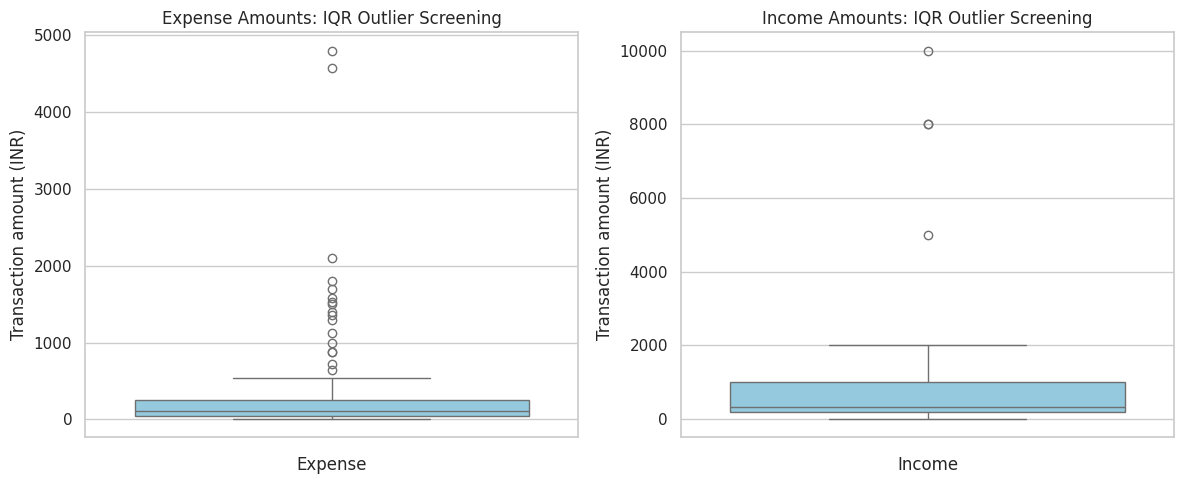

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, transaction_type in zip(axes, ["Expense", "Income"]):
    values = df.loc[
        df["Income/Expense"].eq(transaction_type) &
        df["outlier_evaluated"],
        "INR"
    ]

    sns.boxplot(y=values, color="skyblue", ax=ax)

    ax.set(
        title=f"{transaction_type} Amounts: IQR Outlier Screening",
        xlabel=transaction_type,
        ylabel="Transaction amount (INR)"
    )

plt.tight_layout()
plt.show()

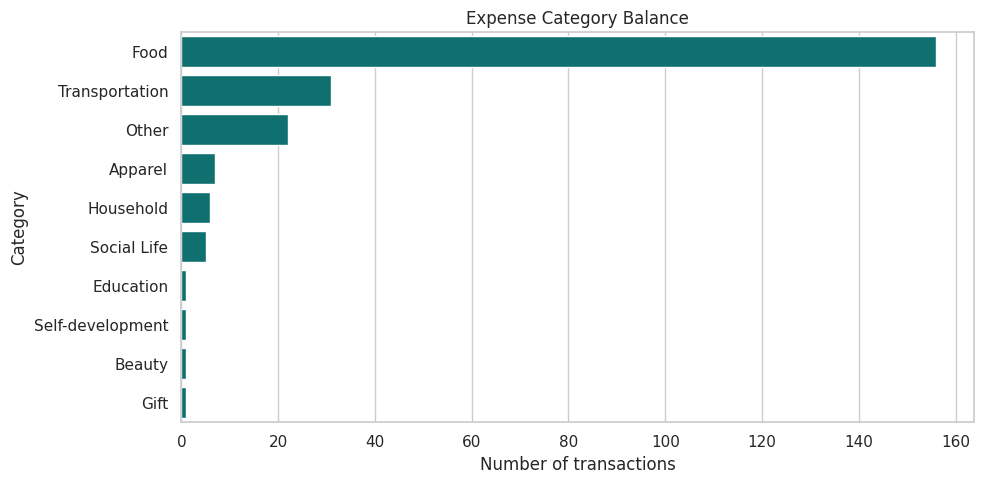

In [ ]:
category_counts = (
    df.loc[df["Income/Expense"].eq("Expense"), "Category"]
    .value_counts()
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index,
    color="teal",
    ax=ax
)

ax.set(
    title="Expense Category Balance",
    xlabel="Number of transactions",
    ylabel="Category"
)

plt.tight_layout()
plt.show()

## 4. PII and Bias Risks

### Privacy Risks

The `Note` field contains personal names and descriptions of financial
activities. `Account` identifies a payment provider or payment channel,
while dates and amounts may reveal aspects of an individual's routine.

Publicly available data can still contain sensitive information.
Free-text notes and account labels are therefore excluded from the
prepared analysis dataset. A missing-note indicator is retained for
data-quality reporting. This reduces exposure but does not guarantee
anonymity because transaction dates and amounts remain.

The original CSV should be handled carefully, and its licence should
be checked before redistribution.

### Bias and Representativeness

According to the uploader, the records come from one individual over
approximately four months. This creates individual-level and
short-period sampling limitations.

Categories with more transactions have greater representation.
Transaction counts also do not equal spending shares: many small food
purchases can occur alongside a few large rent payments.

The data should not be used to generalize to all consumers, other
countries or long-term spending patterns. Omitted or incorrectly
recorded transactions cannot be identified reliably from this file alone.

In [ ]:
# Exclude sensitive free-text and account labels from prepared data.
df_clean = df.drop(columns=["Note", "Account"], errors="ignore").copy()

log_action(
    "Excluded Note and Account from prepared data",
    "Reduce exposure of personal names and payment-provider details.",
    len(df),
    len(df_clean)
)

before_after = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Entirely missing columns",
        "Missing cells in Date, INR and Amount"
    ],
    "Before": [
        len(df_raw),
        df_raw.shape[1],
        int(df_raw.isna().all().sum()),
        int(df_raw[["Date", "INR", "Amount"]].isna().sum().sum())
    ],
    "After": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.isna().all().sum()),
        int(df_clean[["Date", "INR", "Amount"]].isna().sum().sum())
    ]
})

display(before_after)
display(pd.DataFrame(cleaning_log))

# Summarize which checks found issues and which did not.
quality_check_summary = pd.DataFrame({
    "Check": [
        "Exact duplicate rows in source",
        "Failed date conversions",
        "Failed INR conversions",
        "Failed Amount conversions",
        "Invalid transaction types",
        "Invalid amount records",
        "INR amount mismatches",
        "Missing notes",
        "IQR outlier candidates retained"
    ],
    "Count": [
        duplicate_count,
        int(df["date_parse_failed"].sum()),
        int(df["inr_parse_failed"].sum()),
        int(df["amount_parse_failed"].sum()),
        int(df["invalid_transaction_type"].sum()),
        int(df["invalid_amount"].sum()),
        int(df["inr_amount_mismatch"].sum()),
        int(df["note_missing"].sum()),
        int(df["outlier_iqr"].sum())
    ],
    "Action / interpretation": [
        "No exact duplicates detected; no rows removed for duplication",
        "No failed conversions; parsed dates retained",
        "No failed conversions; numeric values retained",
        "No failed conversions; numeric values retained",
        "No invalid labels detected",
        "Flagged for review if present",
        "Flagged for review if present",
        "Retained and flagged, not imputed",
        "Retained because statistical outliers are not necessarily errors"
    ]
})

display(quality_check_summary)

print("Final quality flags:")
display(
    df_clean[[
        "note_missing",
        "date_parse_failed",
        "inr_parse_failed",
        "amount_parse_failed",
        "invalid_transaction_type",
        "invalid_amount",
        "inr_amount_mismatch",
        "outlier_iqr"
    ]].sum().rename("Flagged records").to_frame()
)

# Verify that the source copy has not been modified.
assert len(df_clean) == len(df_raw), "Unexpected row removal."

print("All original rows retained.")
print("Prepared data preview:")
display(df_clean.head())


,Metric,Before,After
0,Rows,277,277
1,Columns,11,15
2,Entirely missing columns,2,0
3,"Missing cells in Date, INR and Amount",0,0


,Action,Reason,Rows before,Rows after
0,"Removed empty columns: ['Subcategory', 'Note.1']",Entirely missing columns contain no usable inf...,277,277
1,Removed Account.1,Its values exactly duplicate Amount.,277,277
2,Flagged and retained IQR outlier candidates,No evidence confirms that these high-value tra...,277,277
3,Excluded Note and Account from prepared data,Reduce exposure of personal names and payment-...,277,277


,Check,Count,Action / interpretation
0,Exact duplicate rows in source,0,No exact duplicates detected; no rows removed ...
1,Failed date conversions,0,No failed conversions; parsed dates retained
2,Failed INR conversions,0,No failed conversions; numeric values retained
3,Failed Amount conversions,0,No failed conversions; numeric values retained
4,Invalid transaction types,0,No invalid labels detected
5,Invalid amount records,0,Flagged for review if present
6,INR amount mismatches,0,Flagged for review if present
7,Missing notes,4,"Retained and flagged, not imputed"
8,IQR outlier candidates retained,21,Retained because statistical outliers are not ...


Final quality flags:


,Flagged records
note_missing,4
date_parse_failed,0
inr_parse_failed,0
amount_parse_failed,0
invalid_transaction_type,0
invalid_amount,0
inr_amount_mismatch,0
outlier_iqr,21


All original rows retained.
Prepared data preview:


,Date,Category,INR,Income/Expense,Amount,Currency,note_missing,date_parse_failed,inr_parse_failed,amount_parse_failed,invalid_transaction_type,invalid_amount,inr_amount_mismatch,outlier_evaluated,outlier_iqr
0,2022-03-02 10:11:00,Food,50.0,Expense,50.0,INR,False,False,False,False,False,False,False,True,False
1,2022-03-02 10:11:00,Other,300.0,Expense,300.0,INR,False,False,False,False,False,False,False,True,False
2,2022-03-01 19:50:00,Food,78.0,Expense,78.0,INR,False,False,False,False,False,False,False,True,False
3,2022-03-01 18:56:00,Transportation,30.0,Expense,30.0,INR,False,False,False,False,False,False,False,True,False
4,2022-03-01 18:22:00,Food,67.0,Expense,67.0,INR,False,False,False,False,False,False,False,True,False


## 5. Conclusion

The dataset is suitable for a limited descriptive review of the recorded
individual's short-term income and expenses, provided the documented
limitations are respected.

The source contains 277 records, two entirely missing columns, four
missing notes, and no exact duplicate rows. The entirely missing columns
and the redundant `Account.1` column were removed. Date and numeric
conversion checks did not fail, and no invalid transaction types,
invalid amounts or INR amount mismatches were detected. These checks
reduce specific data-quality concerns, but do not prove that every
transaction is complete or correct.

Separate IQR screening identified 17 expense and 4 income outlier
candidates. They were flagged and retained because statistical
extremeness alone does not establish an error. The summary table reports
the counts for checks that found no issue as well as records that were
flagged for review.

`INR` was used as the common field for amount comparisons, but the
dataset does not document the exchange-rate source or conversion method.
Therefore, the accuracy of the foreign-currency conversion remains
unverified. Free-text notes and account labels were excluded from the
prepared dataset to reduce privacy exposure.

Remaining limitations include single-person coverage, a short observation
period, possible unrecorded transactions, and an undocumented
foreign-currency conversion method. The data can support exploratory
budget review for this individual. It is insufficient to establish a
reliable general-purpose prediction or recommendation system for a wider
population.
